# 06. Implicação de receita

Fase 6. O que acontece com a receita de bilheteria de mercado de **um
setor** quando o clube muda o preço **desse setor em relação aos outros
setores do mesmo jogo**, segundo a elasticidade da Fase 5, com a incerteza
do beta propagada. **Não é cenário de alta geral de preço. Não calcula
preço ótimo e não recomenda preço.**

**O beta de E2 é elasticidade de setor, não de mercado.** O efeito fixo de
partida absorve todo movimento de preço comum aos setores do jogo, então o
beta é identificado só pelo preço de um setor relativo aos outros do mesmo
jogo. Parte da queda de público quando um setor encarece são pessoas que
trocam de setor; numa alta geral não há para onde trocar. A elasticidade de
mercado é, portanto, menor em módulo que a de setor, e aplicar o beta de
setor a uma alta geral superestimaria a perda de público e subestimaria o
ganho de receita. Esta base não mede a elasticidade agregada e não tem como
medir: exigiria variação de preço entre partidas com demanda constante, que
é o problema de endogeneidade que o efeito fixo existe para resolver.

Unidade: setor x jogo, a mesma da Fase 5. Valores em R$ da temporada 2026
(IPCA anual, `referencias/ipca.csv`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from linearmodels import PanelOLS

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = RAIZ / "figuras" / "06_receita"
FIG.mkdir(parents=True, exist_ok=True)

base = pd.read_csv(RAIZ / "data" / "03_processed" / "boletins.csv")
ipca = pd.read_csv(RAIZ / "referencias" / "ipca.csv").set_index("ano").ipca_variacao_anual_pct
ULTIMA = base.ano.max()
fator = {t: float(np.prod([1 + ipca[y] / 100 for y in range(t, ULTIMA)])) for t in sorted(base.ano.unique())}

# Mesma construção da Fase 5 (notebooks/05_modelo.ipynb).
merc = base[base.regime == "mercado"]
chave = ["ano", "jogo", "mandante", "setor"]
precos = merc[~merc.preco_regulado].groupby(chave).preco.agg(["nunique", "first"])
agregado = merc.groupby(chave).agg(q=("vendidos", "sum"), arrecadacao=("arrecadacao", "sum"))
d = (precos[precos["nunique"] == 1]["first"].rename("preco").to_frame()
     .join(agregado, how="inner").reset_index())
d["id_setor"] = d.mandante + " | " + d.setor
d["id_jogo"] = d.ano.astype(str) + "_" + d.jogo.astype(str)
d["lq"] = np.log(d.q)
d["lp"] = np.log(d.preco)
d["fator_2026"] = d.ano.map(fator)
d["preco_real"] = d.preco * d.fator_2026
print(f"Unidades: {len(d):,}  jogos: {d.id_jogo.nunique()}  setores: {d.id_setor.nunique()}")

Unidades: 2,212  jogos: 387  setores: 337


## Betas usados

Reestimados aqui com a mesma especificação da Fase 5 (E2: efeitos fixos de
partida e setor, erro agrupado por jogo), para que este notebook não
dependa de números copiados.

In [2]:
def estimar(df):
    df = df.copy()
    df["t"] = pd.factorize(df.id_jogo)[0]
    p = df.set_index(["id_setor", "t"])
    r = PanelOLS(p.lq, p[["lp"]], entity_effects=True, time_effects=True).fit(
        cov_type="clustered", cluster_time=True)
    ic = r.conf_int().loc["lp"]
    return {"beta": r.params.lp, "ic95_inf": ic.lower, "ic95_sup": ic.upper, "n_obs": int(r.nobs),
            "n_jogos": df.id_jogo.nunique(), "n_setores": df.id_setor.nunique()}


ocupacao = d.q / d.groupby("id_setor").q.transform("max")
contagem = d.id_setor.map(d.id_setor.value_counts())
betas = pd.DataFrame({
    "E2 (principal)": estimar(d),
    "E2 sem ocupação aparente >= 0,90": estimar(d[ocupacao < 0.90]),
    "E2, setores com >= 5 observações": estimar(d[contagem >= 5]),
}).T
print(betas.round(4).to_string())

                                    beta  ic95_inf  ic95_sup   n_obs  n_jogos  n_setores
E2 (principal)                   -0.4680   -0.8831   -0.0529  2212.0    387.0      337.0
E2 sem ocupação aparente >= 0,90 -0.8114   -1.3113   -0.3115  1765.0    364.0      215.0
E2, setores com >= 5 observações -0.5286   -0.9399   -0.1172  1895.0    349.0      150.0


## 1. Receita de bilheteria de mercado

Receita por setor-jogo = preço x q, em R$ de 2026, mostrada aqui só como
diagnóstico. `preco` é o preço do subconjunto identificador (a Inteira) e
`q` soma todos os ingressos de mercado do setor, inclusive Meia. Por isso
preço x q **não é a arrecadação do boletim**: valoriza a Meia pelo preço da
Inteira e fica acima da arrecadação de mercado das mesmas linhas. **Toda
tabela de resultado em R$ usa a arrecadação de mercado do boletim.**

In [3]:
d["receita"] = d.preco_real * d.q
d["arrecadacao_real"] = d.arrecadacao * d.fator_2026
print(f"Receita preço x q (R$ 2026): {d.receita.sum():,.0f}")
print(f"Arrecadação de mercado do boletim nas mesmas unidades (R$ 2026): {d.arrecadacao_real.sum():,.0f}")
print(f"Razão: {d.receita.sum() / d.arrecadacao_real.sum():.3f}")
print()
print("Distribuição da receita por setor-jogo (R$ 2026):")
print(d.receita.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(0).to_string())
print()
print("Por temporada:")
print(d.groupby("ano").agg(unidades=("receita", "size"), receita=("receita", "sum"),
                           arrecadacao=("arrecadacao_real", "sum")).round(0).to_string())

Receita preço x q (R$ 2026): 228,615,220
Arrecadação de mercado do boletim nas mesmas unidades (R$ 2026): 164,201,387
Razão: 1.392

Distribuição da receita por setor-jogo (R$ 2026):
count       2212.0
mean      103352.0
std       165324.0
min           46.0
10%         3000.0
25%         9626.0
50%        38641.0
75%       131863.0
90%       274021.0
max      1906064.0

Por temporada:
      unidades     receita  arrecadacao
ano                                    
2023       630  63303983.0   45413310.0
2024       602  71274937.0   49638148.0
2025       593  54122311.0   39274213.0
2026       387  39913990.0   29875716.0


## 2 e 3. Variação de receita de um setor com preço relativo alterado

Com elasticidade constante, a receita do setor é proporcional a
p^(1+beta). Uma variação Δ no preço do setor, mantidos os preços dos demais
setores do jogo, dá variação de receita (1+Δ)^(1+beta) - 1, **a mesma em
todo setor-jogo**. Os valores em R$ aplicam esse percentual à arrecadação
de mercado do boletim. Somar o efeito sobre todos os setores ao mesmo tempo
não é uma alta geral: o beta de setor não vale para ela. A conta usa o
beta pontual e os dois extremos do IC 95% de cada especificação.

In [4]:
variacoes = [-0.20, -0.10, 0.10, 0.20]
linhas = []
for nome, b in betas.iterrows():
    for dp in variacoes:
        linha = {"especificacao": nome, "variacao_preco": f"{dp:+.0%}"}
        for sufixo, beta in [("ic_inf", b.ic95_inf), ("pontual", b.beta), ("ic_sup", b.ic95_sup)]:
            variacao = (1 + dp) ** (1 + beta) - 1
            linha[f"pct_{sufixo}"] = 100 * variacao
            linha[f"R$_milhoes_{sufixo}"] = d.arrecadacao_real.sum() * variacao / 1e6
        linhas.append(linha)
tabela = pd.DataFrame(linhas)
pd.set_option("display.width", 220)
print("Variação de receita implicada: beta no limite inferior do IC, pontual e no limite superior")
print("Percentual:")
print(tabela[["especificacao", "variacao_preco", "pct_ic_inf", "pct_pontual", "pct_ic_sup"]].round(2).to_string(index=False))
print()
print(f"Em R$ milhões de 2026, sobre a arrecadação de mercado do boletim (R$ {d.arrecadacao_real.sum():,.0f}):")
print(tabela[["especificacao", "variacao_preco", "R$_milhoes_ic_inf", "R$_milhoes_pontual", "R$_milhoes_ic_sup"]].round(2).to_string(index=False))
tabela.round(4).to_csv(FIG / "variacao_receita.csv", index=False)

Variação de receita implicada: beta no limite inferior do IC, pontual e no limite superior
Percentual:
                   especificacao variacao_preco  pct_ic_inf  pct_pontual  pct_ic_sup
                  E2 (principal)           -20%       -2.57       -11.19      -19.05
                  E2 (principal)           -10%       -1.22        -5.45       -9.50
                  E2 (principal)           +10%        1.12         5.20        9.45
                  E2 (principal)           +20%        2.15        10.19       18.85
E2 sem ocupação aparente >= 0,90           -20%        7.19        -4.12      -14.24
E2 sem ocupação aparente >= 0,90           -10%        3.33        -1.97       -7.00
E2 sem ocupação aparente >= 0,90           +10%       -2.92         1.81        6.78
E2 sem ocupação aparente >= 0,90           +20%       -5.52         3.50       13.38
E2, setores com >= 5 observações           -20%       -1.33        -9.99      -17.88
E2, setores com >= 5 observações           -10%

## 4. Faixa de preço observada

A conta não deve ser lida fora da faixa de preço já praticada. Faixa de
cada setor: mínimo e máximo do preço real (R$ 2026) do setor na base.
Abaixo, quantos setor-jogos sairiam da faixa do próprio setor com cada
variação.

In [5]:
faixa = d.groupby("id_setor").preco_real.agg(minimo="min", maximo="max", jogos="size")
faixa["razao_max_min"] = faixa.maximo / faixa.minimo
d = d.join(faixa[["minimo", "maximo"]], on="id_setor")
print(f"Setores: {len(faixa)}; com faixa nula (um só preço real): {(faixa.minimo == faixa.maximo).sum()}")
print("Razão entre preço máximo e mínimo do setor:")
print(faixa.razao_max_min.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(3).to_string())
print()
for dp in variacoes:
    novo = d.preco_real * (1 + dp)
    fora = (novo > d.maximo * (1 + 1e-9)) | (novo < d.minimo * (1 - 1e-9))
    print(f"{dp:+.0%}: {fora.sum():,} de {len(d):,} setor-jogos saem da faixa do setor ({fora.mean():.1%})")
faixa.round(2).sort_values("razao_max_min").to_csv(FIG / "faixa_preco_por_setor.csv")

Setores: 337; com faixa nula (um só preço real): 142
Razão entre preço máximo e mínimo do setor:
count    337.000
mean       1.920
std        1.453
min        1.000
25%        1.000
50%        1.400
75%        2.390
90%        3.656
max       12.500

-20%: 1,135 de 2,212 setor-jogos saem da faixa do setor (51.3%)
-10%: 947 de 2,212 setor-jogos saem da faixa do setor (42.8%)
+10%: 582 de 2,212 setor-jogos saem da faixa do setor (26.3%)
+20%: 663 de 2,212 setor-jogos saem da faixa do setor (30.0%)


## 5. Por que não há preço ótimo aqui

Com beta maior que -1, a receita p^(1+beta) cresce sem limite com o preço:
no modelo, subir o preço do setor sempre aumenta a receita do setor. Isso é consequência da
forma funcional de elasticidade constante, não do mundo. Fora da faixa
observada a elasticidade não é conhecida, e não há base para supor que siga
constante. Além disso, o limite inferior do IC da especificação filtrada
por censura fica abaixo de -1: nesse extremo, subir preço reduz a receita.
O sinal da variação de receita para aumento de preço não é robusto entre
especificações.

## Gráfico

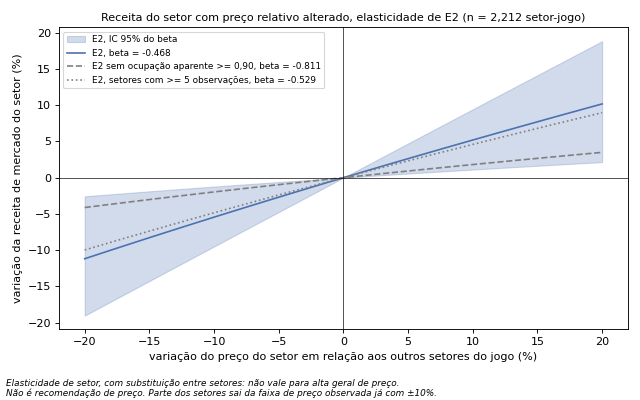

In [6]:
grade = np.linspace(-0.20, 0.20, 81)
b = betas.loc["E2 (principal)"]
fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(100 * grade, 100 * ((1 + grade) ** (1 + b.ic95_inf) - 1),
                100 * ((1 + grade) ** (1 + b.ic95_sup) - 1), color="#4C72B0", alpha=0.25,
                label="E2, IC 95% do beta")
ax.plot(100 * grade, 100 * ((1 + grade) ** (1 + b.beta) - 1), color="#4C72B0",
        label=f"E2, beta = {b.beta:.3f}")
for nome, estilo in [("E2 sem ocupação aparente >= 0,90", "--"), ("E2, setores com >= 5 observações", ":")]:
    bb = betas.loc[nome].beta
    ax.plot(100 * grade, 100 * ((1 + grade) ** (1 + bb) - 1), estilo, color="gray",
            label=f"{nome}, beta = {bb:.3f}")
ax.axhline(0, color="black", lw=0.6)
ax.axvline(0, color="black", lw=0.6)
ax.set_xlabel("variação do preço do setor em relação aos outros setores do jogo (%)")
ax.set_ylabel("variação da receita de mercado do setor (%)")
ax.set_title(f"Receita do setor com preço relativo alterado, elasticidade de E2 (n = {int(b.n_obs):,} setor-jogo)",
             fontsize=10)
ax.legend(fontsize=8)
fig.text(0.01, 0.035, "Elasticidade de setor, com substituição entre setores: não vale para alta geral de preço.",
         fontsize=8, style="italic")
fig.text(0.01, 0.01, "Não é recomendação de preço. Parte dos setores sai da faixa de preço observada já com ±10%.",
         fontsize=8, style="italic")
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(FIG / "variacao_receita.png", dpi=150)
plt.show()

## Por que isso não é recomendação de preço

A conta acima responde só a uma pergunta estreita: quanto a receita de
bilheteria de mercado de um setor variaria se o clube mudasse o preço desse
setor em relação aos outros do mesmo jogo, dentro da faixa já praticada.
Ela ignora:

- **Consumo dentro do estádio.** Alimentação, bebida e produtos dependem do
  público presente, não do preço do ingresso. Menos público é menos
  consumo.
- **Conversão de sócio.** Ingresso avulso caro é também argumento de venda
  do programa de sócio-torcedor. A receita de sócio não está nesta conta.
- **Formação de torcedor no longo prazo.** Preço que afasta o público
  jovem ou de menor renda hoje reduz a base de torcedores de amanhã.
- **Ambiente.** Estádio cheio tem valor esportivo, de transmissão e de
  patrocínio que a bilheteria não mede.
- **Capacidade.** Sem a capacidade do setor, não se sabe quem esgotou. A
  censura puxa a elasticidade para zero e o filtro por ocupação aparente é
  proxy, não correção.
- **O clube pode estar escolhendo isso de propósito.** Preço abaixo do que
  maximizaria a bilheteria pode ser decisão consciente, pelos motivos
  acima. Elasticidade menor que 1 em módulo não prova que o clube erra.